# AeroGuard AI · Model comparison

This notebook compares the saved LSTM with a Random Forest Regressor and an MLP Regressor. The LSTM scores and predictions come from the existing benchmark. Run `python src/classical_baselines.py` from the repository root to regenerate the two fitted estimators and this notebook's inputs in `models/comparative/`.

## Engine split and inputs

The benchmark reconstructs the LSTM split from its saved seed, validation fraction and engine IDs. Each model sees the same 50-cycle windows and the same RUL target capped at 125 cycles during training and validation. The two new estimators consume six statistics per channel: mean, population standard deviation, minimum, maximum, latest reading and the least-squares slope per cycle. These statistics use the 21 sensors and three operating settings in each window. They exclude engine IDs, timestamps beyond the endpoint and future observations.

The forest uses raw statistics. Standardization for the MLP uses the training windows and training targets. The 707 test predictions are joined by subset and engine ID, with exact agreement checked on both sets of RUL labels.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / 'models').is_dir():
    root = root.parent
out = root / 'models' / 'comparative'
with (out / 'evaluation.json').open(encoding='utf-8') as handle:
    report = json.load(handle)
table = pd.read_csv(out / 'comparison.csv').set_index(['model', 'dataset'])
predictions = pd.read_csv(out / 'test_predictions.csv')

split = report['split']
assert set(split['training_engine_ids']).isdisjoint(split['validation_engine_ids'])
assert len(predictions) == 707 and not predictions.duplicated(['dataset', 'engine_id']).any()
assert (predictions['actual_raw'].clip(upper=report['rul_cap']) == predictions['actual_capped']).all()
display(pd.DataFrame({
    'engines': [len(split['training_engine_ids']), len(split['validation_engine_ids']), len(predictions)],
    'windows': [split['training_windows'], split['validation_windows'], len(predictions)],
}, index=['Training', 'Validation', 'Test']))
display(predictions.groupby('dataset').size().rename('Test engines').to_frame())

,engines,windows
Training,567,99714
Validation,142,25904
Test,707,707


,Test engines
dataset,
FD001,100
FD002,259
FD003,100
FD004,248


## Random Forest and MLP training

The forest averages 96 depth-limited regression trees. Each tree uses a bootstrap sample of 85% of the training windows and considers half the features at each split. A six-sample leaf minimum limits the tree size. The forest uses four CPU workers and a fixed seed.

The MLP has 128 and 64 ReLU units, Adam and L2 regularization. Each incremental call completes one training epoch. Validation RMSE in cycles selects the saved epoch, with a patience of 12 epochs and a budget of 100. The validation engines stay fixed throughout training. The plotted training objective is measured on standardized targets.

Times are wall-clock measurements of one pooled fit per model. The forest fit excludes feature preparation and its validation score. The MLP time includes scaling and validation-based epoch selection. The saved LSTM time includes validation on the RTX 4060. The devices and timed scopes differ.

,device,seconds,validation_rmse,best_epoch,scope
LSTM,CUDA,164.291,14.677,15.0,"saved training loop, including validation"
Random Forest,CPU,144.195,19.657,NaN,fit only
MLP,CPU,23.301,14.592,37.0,"scaling, fit and validation selection"


Shared statistical feature preparation: 4.2 s


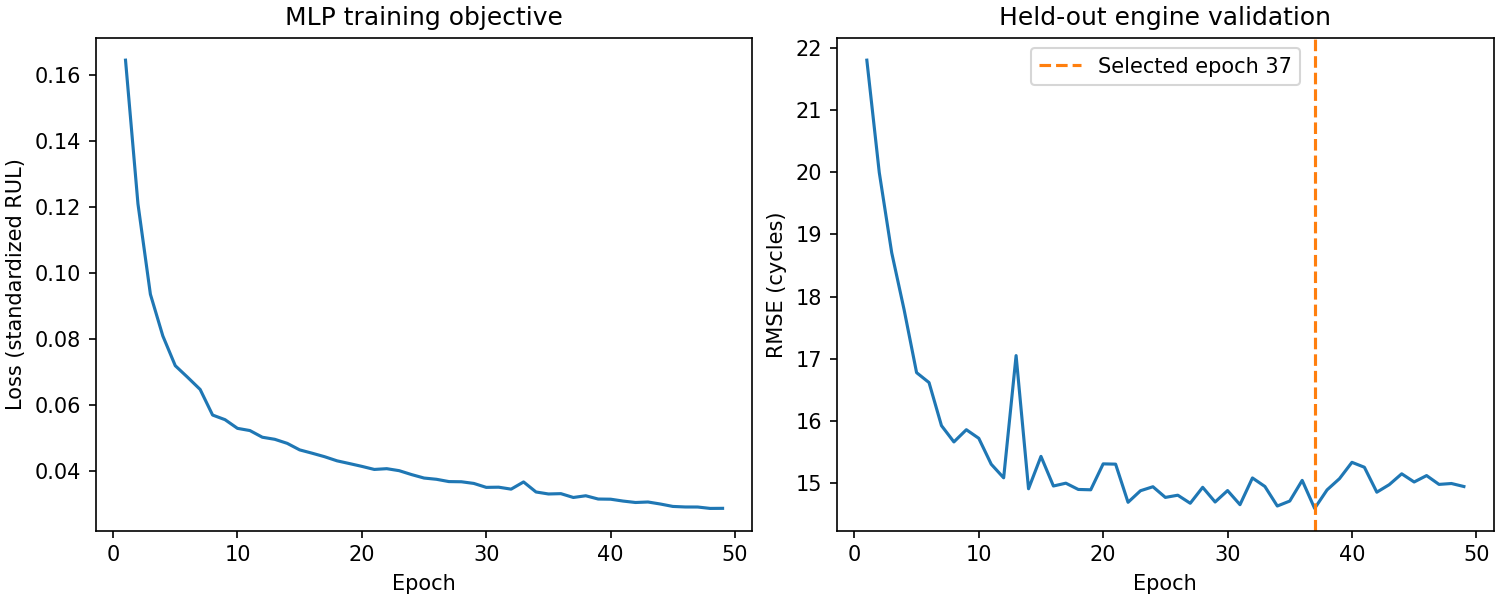

In [2]:
timing = pd.DataFrame(report['training']).T
display(timing[['device', 'seconds', 'validation_rmse', 'best_epoch', 'scope']]
        .astype({'seconds': float, 'validation_rmse': float, 'best_epoch': float}).round(3))
print(f"Shared statistical feature preparation: {report['feature_preparation_seconds']:.1f} s")
curves = pd.read_csv(out / 'mlp_history.csv')
mlp = report['training']['MLP']
assert mlp['best_epoch'] == curves.loc[curves['validation_rmse'].idxmin(), 'epoch']
display(Image(filename=str(out / 'mlp_learning_curves.png')))

,feature,importance
0,sensor_11_max,0.344217
1,sensor_4_max,0.130028
2,sensor_13_max,0.094413
3,sensor_9_max,0.061541
4,sensor_17_max,0.058044
5,sensor_14_max,0.025411
6,sensor_3_max,0.020079
7,sensor_15_max,0.017767
8,sensor_2_max,0.011780
9,sensor_8_max,0.011174


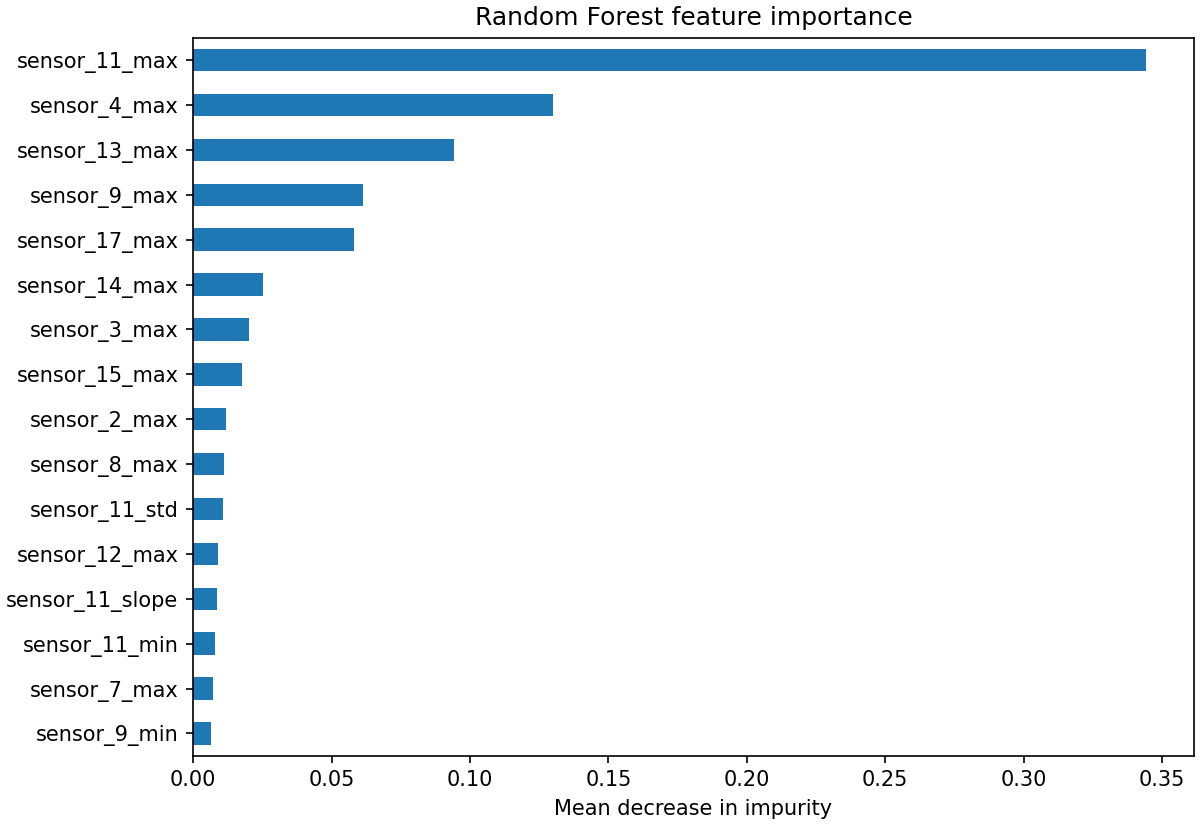

In [3]:
importance = pd.read_csv(out / 'random_forest_feature_importance.csv')
display(importance.head(12))
display(Image(filename=str(out / 'random_forest_feature_importance.png')))

Forest importance measures the average reduction in squared-error impurity attributed to a feature. Correlated channels and correlated summaries can share importance. These scores describe the fitted forest's splits and do not establish a physical cause of degradation.

## Held-out test results

Every test engine contributes one prediction. Capped and uncapped scores use identical predictions with two label definitions. RMSE and MAE are in cycles. The NASA score penalizes overestimates more heavily and is summed across engines. Pooled metrics are calculated across individual engines, giving more weight to the larger subsets.

Capped RUL


engines    rmse     mae     r2  nasa_score
model         dataset                                            
LSTM          FD001        100  14.388  10.469  0.871     309.497
              FD002        259  13.697   9.623  0.898     881.916
              FD003        100  14.324   9.916  0.866     938.215
              FD004        248  15.236  10.895  0.874    1023.767
              pooled       707  14.438  10.230  0.882    3153.395
Random Forest FD001        100  13.548  10.174  0.886     291.763
              FD002        259  19.745  15.586  0.789    2108.432
              FD003        100  12.603   8.896  0.896     395.222
              FD004        248  20.150  15.236  0.780    2325.370
              pooled       707  18.267  13.752  0.812    5120.787
MLP           FD001        100  13.978   9.833  0.878     327.343
              FD002        259  14.230  10.652  0.890     997.246
              FD003        100  11.957   9.205  0.907     216.900
              FD004        248  15.233  11.017  0.874    1239.323
              pooled       707  14.263  10.460  0.885    2780.811

Uncapped RUL


engines    rmse     mae     r2  nasa_score
model         dataset                                            
LSTM          FD001        100  15.770  11.539  0.856     351.444
              FD002        259  26.396  17.110  0.759    7354.641
              FD003        100  16.153  11.471  0.848    1027.402
              FD004        248  27.536  19.456  0.745    5635.167
              pooled       707  24.358  16.347  0.773   14368.654
Random Forest FD001        100  14.940  11.244  0.871     331.122
              FD002        259  32.288  23.080  0.640   28876.267
              FD003        100  14.426  10.456  0.879     441.307
              FD004        248  32.035  23.930  0.655   11631.652
              pooled       707  28.335  19.919  0.692   41280.348
MLP           FD001        100  15.201  10.903  0.866     360.183
              FD002        259  24.893  17.301  0.786    4979.950
              FD003        100  14.166  10.765  0.883     283.150
              FD004        248  26.475  18.440  0.764    8959.916
              pooled       707  23.107  15.871  0.795   14583.199

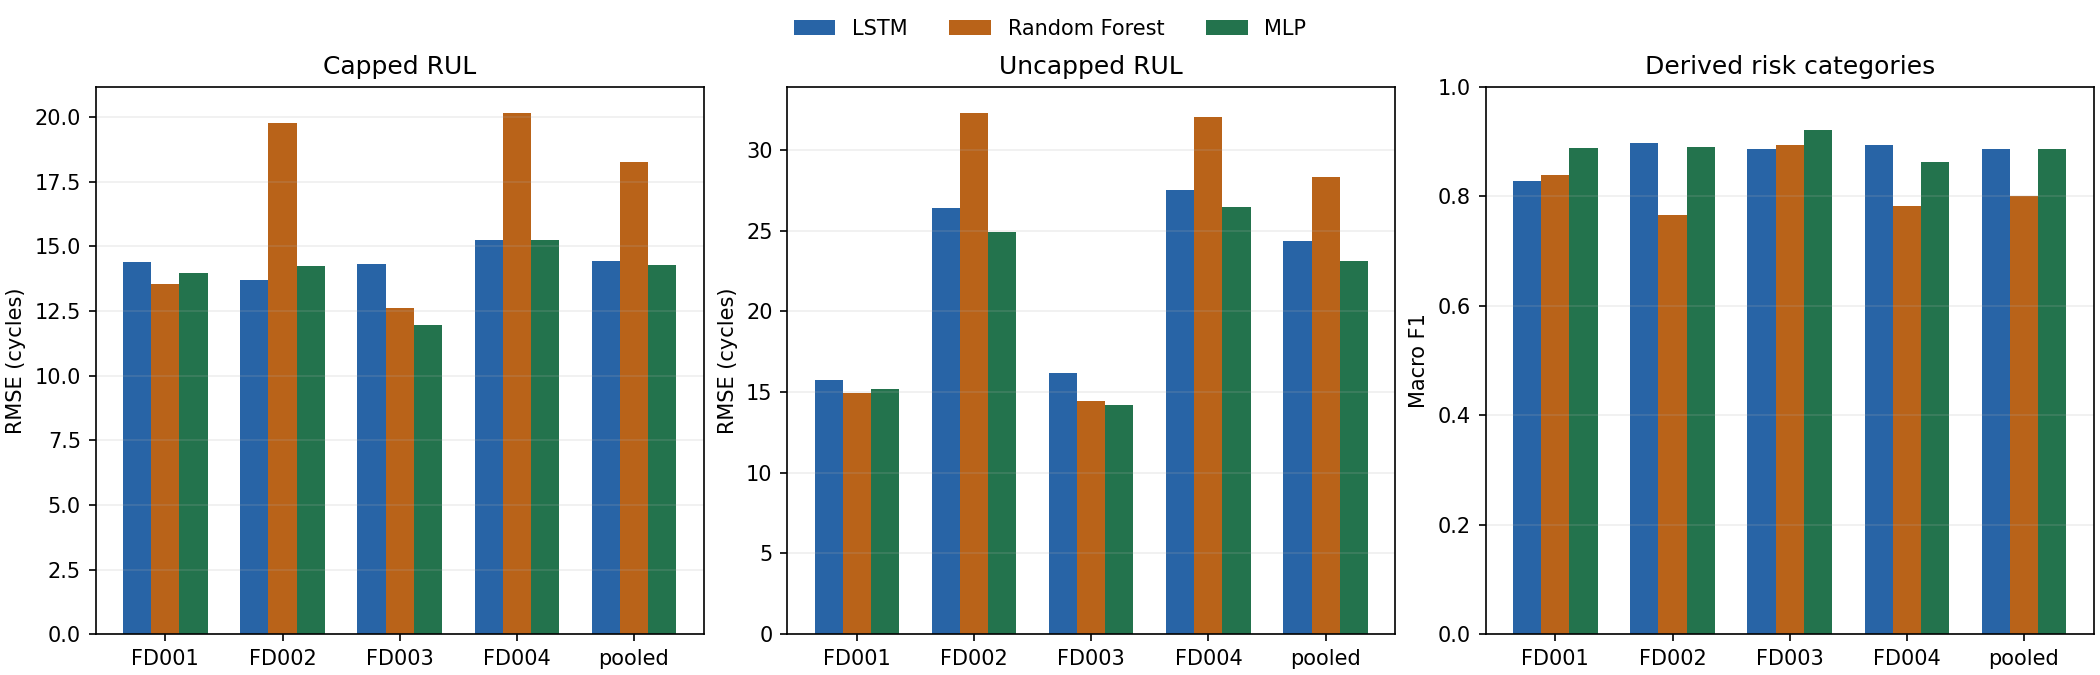

In [4]:
for label in ('capped', 'uncapped'):
    print(f'{label.title()} RUL')
    columns = [f'{label}_{metric}' for metric in ('rmse', 'mae', 'r2', 'nasa_score')]
    display(table[['engines'] + columns].rename(columns=lambda name: name.removeprefix(label + '_')).round(3))
display(Image(filename=str(out / 'model_comparison.png')))

## Risk categories derived from RUL

Critical means 30 cycles or fewer, Warning means more than 30 and at most 60, and Healthy means more than 60. The 125-cycle cap does not change these class labels. Macro metrics give each class equal weight. Confusion matrices show actual categories in rows and predictions in columns. The categories are for interpreting the simulated benchmark.

risk_accuracy  risk_macro_precision  risk_macro_recall  \
model         dataset                                                           
LSTM          FD001            0.900                 0.849              0.812   
              FD002            0.931                 0.898              0.898   
              FD003            0.910                 0.913              0.866   
              FD004            0.931                 0.893              0.894   
              pooled           0.924                 0.893              0.880   
Random Forest FD001            0.900                 0.854              0.843   
              FD002            0.838                 0.774              0.760   
              FD003            0.920                 0.930              0.872   
              FD004            0.867                 0.803              0.764   
              pooled           0.868                 0.816              0.789   
MLP           FD001            0.930                 0.895              0.883   
              FD002            0.931                 0.916              0.874   
              FD003            0.940                 0.944              0.903   
              FD004            0.915                 0.876              0.851   
              pooled           0.926                 0.902              0.873   

                       risk_macro_f1  
model         dataset                 
LSTM          FD001            0.828  
              FD002            0.898  
              FD003            0.887  
              FD004            0.894  
              pooled           0.886  
Random Forest FD001            0.840  
              FD002            0.766  
              FD003            0.893  
              FD004            0.782  
              pooled           0.801  
MLP           FD001            0.888  
              FD002            0.890  
              FD003            0.922  
              FD004            0.862  
              pooled           0.886

Predicted                       Critical  Warning  Healthy
Model         Dataset Actual                              
LSTM          FD001   Critical        22        3        0
                      Warning          1        8        5
                      Healthy          0        1       60
              FD002   Critical        58        3        0
                      Warning          3       32        6
                      Healthy          0        6      151
              FD003   Critical        18        2        0
                      Warning          0       15        6
                      Healthy          0        1       58
              FD004   Critical        49        4        0
                      Warning          3       30        5
                      Healthy          0        5      152
              pooled  Critical       147       12        0
                      Warning          7       85       22
                      Healthy          0       13      421
Random Forest FD001   Critical        19        6        0
                      Warning          0       11        3
                      Healthy          0        1       60
              FD002   Critical        50        9        2
                      Warning          5       22       14
                      Healthy          0       12      145
              FD003   Critical        19        1        0
                      Warning          1       14        6
                      Healthy          0        0       59
              FD004   Critical        42        9        2
                      Warning          5       20       13
                      Healthy          0        4      153
              pooled  Critical       130       25        4
                      Warning         11       67       36
                      Healthy          0       17      417
MLP           FD001   Critical        22        3        0
                      Warning          0       11        3
                      Healthy          0        1       60
              FD002   Critical        60        1        0
                      Warning          4       27       10
                      Healthy          0        3      154
              FD003   Critical        18        2        0
                      Warning          0       17        4
                      Healthy          0        0       59
              FD004   Critical        47        6        0
                      Warning          3       26        9
                      Healthy          0        3      154
              pooled  Critical       147       12        0
                      Warning          7       81       26
                      Healthy          0        7      427

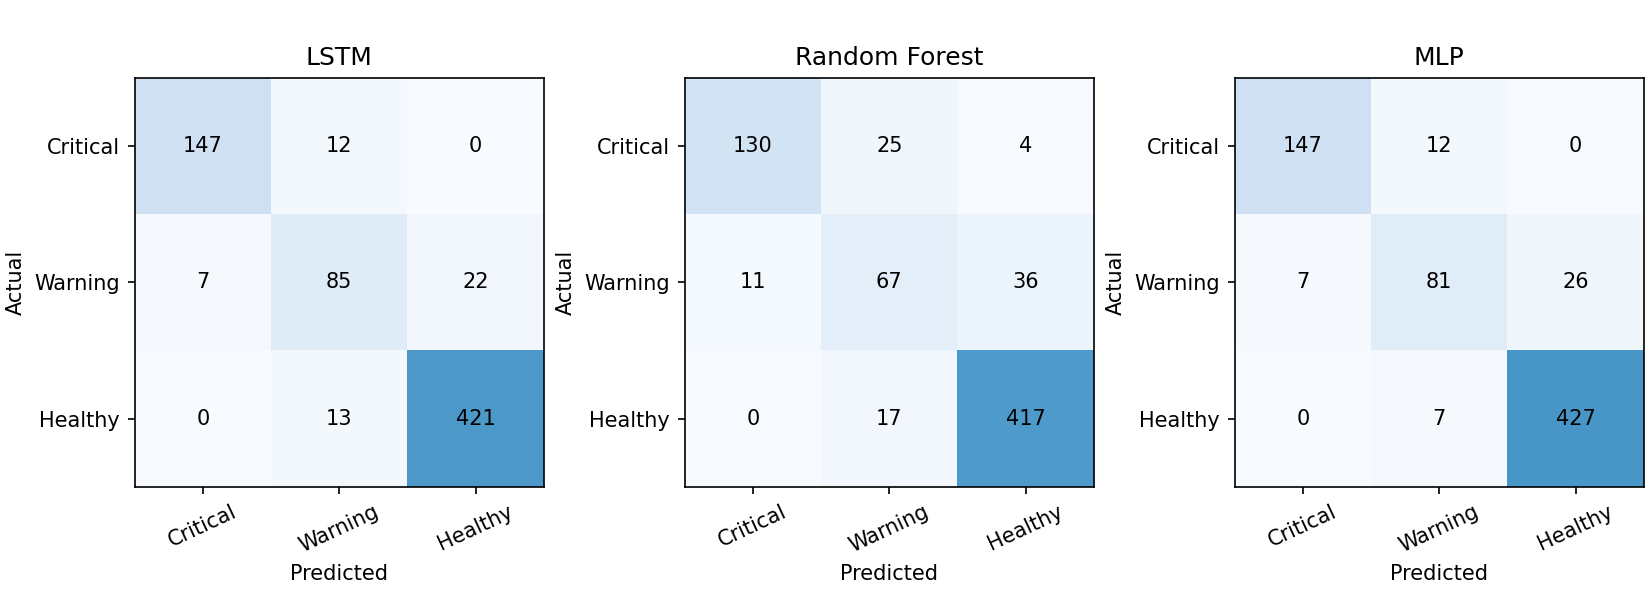

In [5]:
display(table[['risk_accuracy', 'risk_macro_precision', 'risk_macro_recall', 'risk_macro_f1']].round(3))
labels = report['results']['LSTM']['pooled']['risk']['labels']
matrices = {
    (model, dataset): pd.DataFrame(metrics['risk']['confusion_matrix'], index=labels, columns=labels)
    for model, datasets in report['results'].items()
    for dataset, metrics in datasets.items()
}
display(pd.concat(matrices, names=['Model', 'Dataset', 'Actual']).rename_axis('Predicted', axis=1))
display(Image(filename=str(out / 'pooled_confusion_matrices.png')))

## Interpretation limits

This comparison uses one engine split, one configuration per new model and simulated C-MAPSS trajectories. Window statistics summarize the shape of each signal, and the LSTM receives ordered cycle-level inputs. Each model learns a capped objective, so uncapped errors include differences between that objective and longer true RUL. The pooled figures can hide differences among subsets and risk groups.